In [1]:
from qiskit import QuantumCircuit
import numpy as np

qc0 = QuantumCircuit(1,1)
qc0.ry(np.pi/3,0)
qc0.measure(0,0)

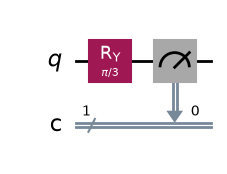

In [3]:
qc0.draw("mpl")

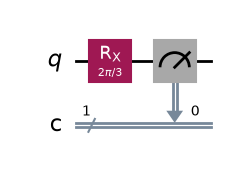

In [4]:
qc1=QuantumCircuit(1,1)
qc1.rx((2*np.pi)/3,0)
qc1.measure(0,0)
qc1.draw("mpl")

In [5]:
from qiskit_ibm_runtime import QiskitRuntimeService

In [6]:
service = QiskitRuntimeService()

In [7]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

backend = service.least_busy()
print(backend.name)

ibm_fez


In [8]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

qc0_isa = pm.run(qc0)
qc1_isa = pm.run(qc1)

In [10]:
sampler = Sampler(mode=backend)
pubs = [qc0_isa,qc1_isa]
jobs = sampler.run(pubs,shots=100)
res = jobs.result()
counts_a = res[0].data.c.get_counts()
counts_b = res[1].data.c.get_counts()

C:\Users\laksh\AppData\Local\Temp\ipykernel_2924\4012940534.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


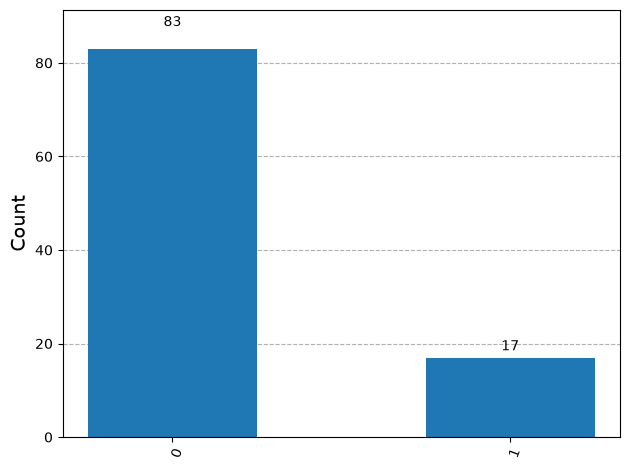

In [11]:
from qiskit.visualization import plot_histogram

plot_histogram(counts_a)

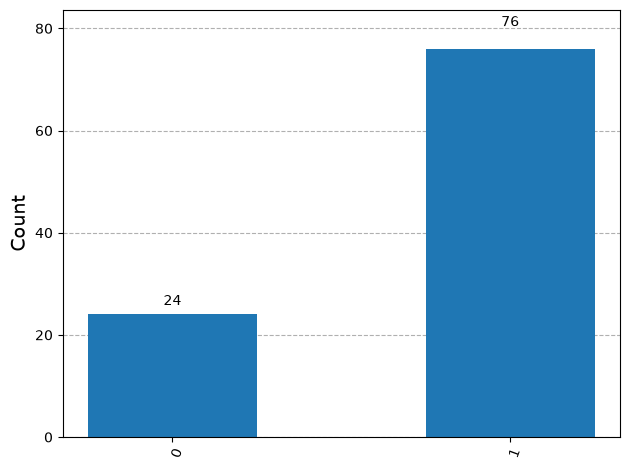

In [12]:
from qiskit.visualization import plot_histogram

plot_histogram(counts_b)

##### In the first circuit rotated the position quantum state of qubit is rotated along y axis with an angle 60.So theoretical probabilities will be
- Probability of 0 - cos^2(30) - 75%
- Probability of 1 - sin^2(30) - 25%

##### In the second circuit, rotated the position of quantum state of a qubit along y-axis with an angle of 120. So theoretical probabilities will be 
- Probability of 0 - cos^2(60) - 25%
- Probability of 1 - sin^2(60) - 75%